# ATP tennis random walk
## Tasks 3 and 4 · IE University

**Question.** If a walker moves from a player to an opponent who beat them, where does the probability settle? Does the starting player change the long-run result?

An arrow goes from the loser to the winner. The dataset pools tour-level results from 2016–2025 and records each directed pair once. We use the original **completed** transition matrix $P$ from Task 1. Its 63 dangling rows use the uniform rule specified in the handout.

**Run this notebook.** Use **Run All** in Colab or Jupyter. It needs NumPy and Matplotlib. If the notebook runs from the project root, it reads both CSVs in `data/`. Otherwise, it reads the same CSVs directly from a pinned revision of the course repository. It rebuilds $P$ so the analysis can run in a fresh session.

**Before running the ranking.** Our Task 2 prediction is that Alexander Zverev will rank highly because he has the most distinct incoming opponents. Djokovic starts in the largest original strongly connected component. Bopanna starts at a dangling player, so his first step is uniform across the network.

In [1]:
import csv
import io
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np

data_dir = Path("data")
csv_names = ("nodes.csv", "edges.csv")
base_url = (
    "https://raw.githubusercontent.com/daniprec/BAM-CPI-LA-Networks/"
    "2109df87176f730065237d42f76675149ff98166/data/atp_tennis/"
)
has_local_data = all((data_dir / name).is_file() for name in csv_names)


def read_course_csv(filename):
    if has_local_data:
        csv_text = (data_dir / filename).read_text(encoding="utf-8")
    else:
        with urlopen(base_url + filename, timeout=30) as response:
            csv_text = response.read().decode("utf-8")
    return list(csv.DictReader(io.StringIO(csv_text)))


players = {
    int(row["node_id"]): row["label"] for row in read_course_csv("nodes.csv")
}
player_ids = {name: node_id for node_id, name in players.items()}
edges = np.array([
    (int(row["source"]), int(row["target"]))
    for row in read_course_csv("edges.csv")
], dtype=int)
n = len(players)
assert set(players) == set(range(n))
assert np.all((0 <= edges) & (edges < n))

# Task 1 setup. Construct the same A and P used in the project script.
A = np.zeros((n, n), dtype=bool)
A[edges[:, 0], edges[:, 1]] = True
out_degree = A.sum(axis=1)
dangling = out_degree == 0
P = np.full((n, n), 1.0 / n)
P[~dangling] = A[~dangling] / out_degree[~dangling, None]

assert (n, len(edges), A.sum()) == (1191, 19986, 19986)
assert np.all(P >= 0) and np.allclose(P.sum(axis=1), 1)
print(f"{n:,} players | {A.sum():,} directed edges | {dangling.sum()} dangling players")

archive = data_dir / "matrices.npz"
if has_local_data and archive.is_file():
    with np.load(archive) as saved:
        np.testing.assert_array_equal(A, saved["A"])
        np.testing.assert_allclose(P, saved["P"], atol=1e-15, rtol=0)
    print("Rebuilt matrices match the existing matrices.npz.")

1,191 players | 19,986 directed edges | 63 dangling players


## Task 3 · Keep taking steps

1. Start with a probability list $x_0$ with a 1 at your starting player and zeros everywhere else.
2. Multiply by $P$ on the right to take one step: $x_{k+1}=x_kP$. The first step from a single player uses that player's row of $P$. From Djokovic, it distributes the initial probability equally among the 51 players who beat him in the dataset. From Bopanna, each player receives $1/1191$.
3. Calculate $\Delta_k=\|x_{k+1}-x_k\|_1=\sum_j |x_{k+1,j}-x_{k,j}|$. This adds the absolute changes for all players.
4. Save the new probabilities and stop at the first change below $10^{-10}$, or after 5,000 updates. In the outputs, step 0 is the starting distribution, and an iteration counts one multiplication by $P$.

In [2]:
def power_iteration(transition, initial, tol=1e-10, max_iter=5000):
    '''Return final vector, update count, distribution history, changes, and stop flag.

    History includes the initial vector at index 0. Change at index 0
    measures the first update.
    '''
    current = np.array(initial, dtype=float, copy=True)
    history = [current]
    changes = []

    for _ in range(max_iter):
        updated = current @ transition
        change = np.abs(updated - current).sum()
        history.append(updated)
        changes.append(change)
        current = updated
        if change < tol:
            break

    converged = bool(changes and changes[-1] < tol)
    return current, len(changes), np.array(history), np.array(changes), converged


tolerance = 1e-10
max_iterations = 5000
starts = ["Novak Djokovic", "Rohan Bopanna"]
runs = {}
print(f"{'Starting player':<20} {'Steps':>5} {'Stopped':>9} {'Last L1 change':>17}")
for name in starts:
    initial = np.zeros(n)
    initial[player_ids[name]] = 1.0
    result = power_iteration(P, initial, tolerance, max_iterations)
    final, steps, history, changes, converged = result
    runs[name] = result
    np.testing.assert_allclose(history.sum(axis=1), 1, atol=1e-12, rtol=0)
    assert np.all(history >= 0)
    assert np.all(changes[:-1] >= tolerance)
    print(f"{name:<20} {steps:>5} {str(converged):>9} {changes[-1]:>17.3e}")

final_gap = np.abs(runs[starts[0]][0] - runs[starts[1]][0]).sum()
print(f"Final L1 difference between the two distributions: {final_gap:.3e}")

Starting player      Steps   Stopped    Last L1 change
Novak Djokovic          28      True         6.628e-11
Rohan Bopanna           33      True         7.305e-11
Final L1 difference between the two distributions: 7.797e-11


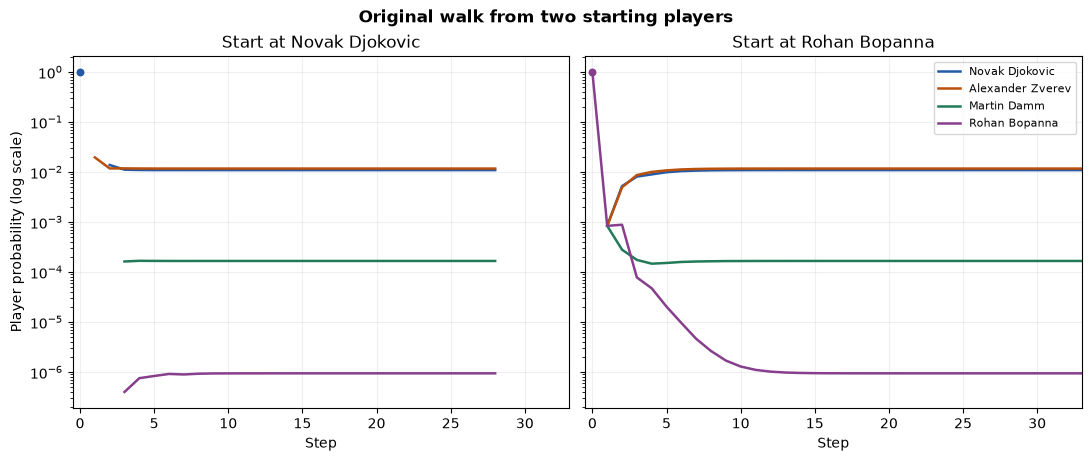

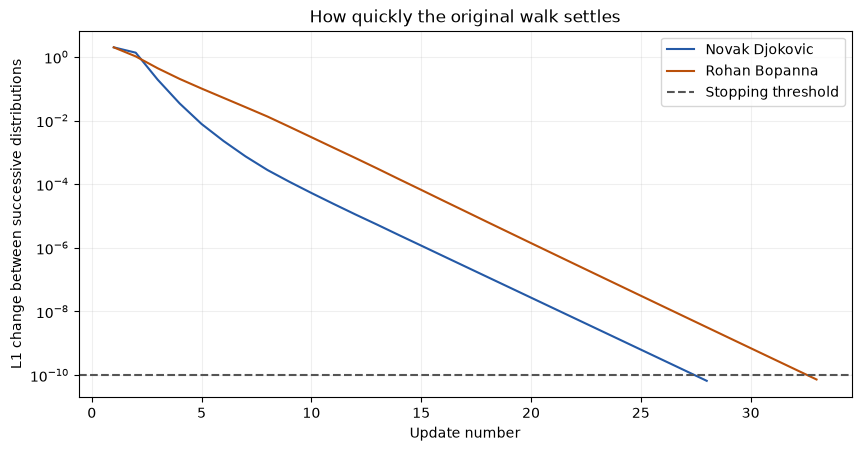

In [3]:
selected_players = [
    "Novak Djokovic", "Alexander Zverev", "Martin Damm", "Rohan Bopanna"
]
player_colors = ["#2459A6", "#BA500A", "#237A58", "#863E8D"]
run_colors = ["#2459A6", "#BA500A"]

fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.5), sharey=True, layout="constrained")
for ax, name in zip(axes, starts):
    history = runs[name][2]
    for player, color in zip(selected_players, player_colors):
        values = history[:, player_ids[player]]
        positive_values = np.where(values > 0, values, np.nan)
        ax.semilogy(positive_values, label=player, color=color, linewidth=1.8)
    start_color = player_colors[selected_players.index(name)]
    ax.scatter(0, 1, color=start_color, s=22, zorder=3)
    ax.set(title=f"Start at {name}", xlabel="Step", xlim=(-0.5, max(run[1] for run in runs.values())))
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Player probability (log scale)")
axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle("Original walk from two starting players", fontweight="bold")
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 4.4), layout="constrained")
for name, color in zip(starts, run_colors):
    changes = runs[name][3]
    ax.semilogy(range(1, len(changes) + 1), changes, color=color, label=name)
ax.axhline(tolerance, color="#555555", linestyle="--", label="Stopping threshold")
ax.set(
    title="How quickly the original walk settles",
    xlabel="Update number",
    ylabel="L1 change between successive distributions",
)
ax.grid(alpha=0.2)
ax.legend()
plt.show()

**What the figures show.** Probabilities initially depend on the starting player and then settle at the same levels to numerical precision. Zero probabilities are omitted on the logarithmic axis. The lower plot tracks the change on each update. Djokovic's run first crosses the tolerance at **28 updates**, and Bopanna's at **33**. Bopanna's first move gives mass to every player, including players well outside the main component, whereas Djokovic's first move gives mass to 51 direct opponents. The two starts give different transient histories. Neither run shows sustained oscillation.

**What this establishes.** Both tested starts converge numerically to the same distribution within the selected tolerance. In Task 4 we check stationarity independently and use the graph to justify convergence from any start.

## Task 4 · Find and check a stationary distribution

A distribution $\pi$ is **stationary** when one more step leaves every player's probability unchanged: $\pi P=\pi$. Taking the transpose of both sides gives $P^{\mathsf T}\pi^{\mathsf T}=\pi^{\mathsf T}$. NumPy gives right eigenvectors as columns, so we take a column from `eig(P.T)` for eigenvalue 1 and normalize it to sum to 1.

We check that the candidate is real, nonnegative and sums to 1. The **stationary residual** $\pi P-\pi$ measures how much one more step would change it. We also compare the candidate with both Task 3 results.

In [4]:
eigenvalues, eigenvectors = np.linalg.eig(P.T)
at_one = np.isclose(eigenvalues, 1.0, atol=1e-8, rtol=0)
assert at_one.sum() == 1

index = np.flatnonzero(at_one)[0]
candidate = np.real_if_close(eigenvectors[:, index])
assert not np.iscomplexobj(candidate)
assert abs(candidate.sum()) > 1e-12

# Dividing by the sum also corrects the arbitrary sign of the eigenvector.
stationary = candidate / candidate.sum()
assert np.all(stationary >= 0) and np.isclose(stationary.sum(), 1)
residual = stationary @ P - stationary
assert np.linalg.norm(residual, ord=1) < 1e-12

print(f"Eigenvalue used: {eigenvalues[index].real:.12f}")
print(f"Stationary sum: {stationary.sum():.12f}")
print(f"Smallest stationary probability: {stationary.min():.8e}")
print(f"L1 stationary residual: {np.linalg.norm(residual, ord=1):.3e}")
for name, result in runs.items():
    error = np.abs(result[0] - stationary).sum()
    print(f"L1 distance from the {name} run to the eigenvector: {error:.3e}")

print("\nTop five players in the original walk")
for rank, player in enumerate(np.argsort(-stationary)[:5], start=1):
    print(f"{rank}. {players[player]:<22} {stationary[player]:.6%}")

Eigenvalue used: 1.000000000000
Stationary sum: 1.000000000000
Smallest stationary probability: 4.73020165e-07
L1 stationary residual: 7.752e-16
L1 distance from the Novak Djokovic run to the eigenvector: 5.901e-11
L1 distance from the Rohan Bopanna run to the eigenvector: 6.495e-11

Top five players in the original walk
1. Alexander Zverev       1.173560%
2. Novak Djokovic         1.093975%
3. Daniil Medvedev        1.069112%
4. Andrey Rublev          1.057069%
5. Taylor Fritz           1.047068%


### Two stationary equations by hand

For a target player $j$, list every arrow pointing to $j$. Each non-dangling source $i$ contributes $\pi_i/d_i$, where $d_i$ is the number of arrows leaving that source. Every dangling source contributes $\pi_i/1191$ to **every** target. Combine those identical contributions as

$$
c=\frac{1}{1191}\sum_{i:\,d_i=0}\pi_i\approx 4.73020\times 10^{-7}.
$$

**Rohan Bopanna.** His one incoming match arrow is from Hong Chung, whose out-degree is 1. So

$$
\pi_{\text{Bopanna}}=\pi_{\text{Hong Chung}}+c
\approx 4.73020\times 10^{-7}+4.73020\times 10^{-7}
=9.46040\times 10^{-7}.
$$

**Martin Damm.** His incoming match arrows are from Zhizhen Zhang, Tommy Paul, and Darwin Blanch. Their out-degrees are 56, 76, and 4. So

$$
\pi_{\text{Damm}}=
\frac{\pi_{\text{Zhang}}}{56}+\frac{\pi_{\text{Paul}}}{76}
+\frac{\pi_{\text{Blanch}}}{4}+c
$$

$$
\approx \frac{0.002576836}{56}+\frac{0.007789578}{76}
+\frac{0.00007142946}{4}+0.000000473020
\approx 0.0001668398.
$$

These are **incoming** contributions to a player's column. In Task 1, Damm's example row showed where probability goes **out** from him.

In [5]:
uniform_contribution = stationary[dangling].sum() / n
for name in ("Rohan Bopanna", "Martin Damm"):
    target = player_ids[name]
    opponents = np.flatnonzero(A[:, target])
    terms = stationary[opponents] / out_degree[opponents]
    expanded_total = terms.sum() + uniform_contribution
    print(f"{name} (column {target})")
    for opponent, term in zip(opponents, terms):
        print(f"  {players[opponent]} / out-degree {out_degree[opponent]}: {term:.9e}")
    print(f"  Shared dangling contribution: {uniform_contribution:.9e}")
    print(f"  Expanded total: {expanded_total:.9e}")
    print(f"  Eigenvector entry: {stationary[target]:.9e}")
    np.testing.assert_allclose(expanded_total, stationary[target], atol=1e-14, rtol=0)

Rohan Bopanna (column 8)
  Hong Chung / out-degree 1: 4.730201647e-07
  Shared dangling contribution: 4.730201647e-07
  Expanded total: 9.460403293e-07
  Eigenvector entry: 9.460403293e-07
Martin Damm (column 1)
  Zhizhen Zhang / out-degree 56: 4.601492374e-05
  Tommy Paul / out-degree 76: 1.024944470e-04
  Darwin Blanch / out-degree 4: 1.785736411e-05
  Shared dangling contribution: 4.730201647e-07
  Expanded total: 1.668397550e-04
  Eigenvector entry: 1.668397550e-04


### Why the two runs agree

First check the support graph of $P$, meaning the arrows for all **positive** entries of the completed matrix. In the original graph, the 63 dangling players were singleton closed components. With the uniform rows, every one of them can now move to any player. The code below checks that Djokovic reaches everyone in $P$, and that everyone can reach Djokovic by reversing the arrows and searching from him. Together those checks establish that any player can reach any other via Djokovic, so $P$ is **irreducible**.

We also check two return paths already present in $A$: Djokovic → Nadal → Djokovic (2 steps), and Djokovic → Zverev → Federer → Djokovic (3 steps). The period must divide both 2 and 3, so it is 1. Since the completed graph is irreducible, this makes the whole chain **aperiodic**.

In [6]:
def reachable(transitions, start):
    '''Return nodes reachable via positive transitions from the starting node.'''
    seen = {start}
    pending = [start]
    while pending:
        current = pending.pop()
        for neighbor in np.flatnonzero(transitions[current]):
            if neighbor not in seen:
                seen.add(neighbor)
                pending.append(neighbor)
    return seen


djokovic = player_ids["Novak Djokovic"]
support = P > 0
from_djokovic = reachable(support, djokovic)
to_djokovic = reachable(support.T, djokovic)
print(f"Reachable from Djokovic in P: {len(from_djokovic)}/{n}")
print(f"Can reach Djokovic in P: {len(to_djokovic)}/{n}")
assert len(from_djokovic) == len(to_djokovic) == n

cycles = [
    ["Novak Djokovic", "Rafael Nadal", "Novak Djokovic"],
    ["Novak Djokovic", "Alexander Zverev", "Roger Federer", "Novak Djokovic"],
]
for cycle in cycles:
    ids = [player_ids[name] for name in cycle]
    assert all(A[source, target] for source, target in zip(ids, ids[1:]))
    print(f"{len(ids) - 1}-step return: " + " → ".join(cycle))

print("\nLeading eigenvalues by modulus")
for value in eigenvalues[np.argsort(-np.abs(eigenvalues))[:5]]:
    print(f"  {value.real:+.8f} {value.imag:+.8f}i   |λ| = {abs(value):.8f}")
other_modulus = np.abs(eigenvalues[~at_one]).max()
print(f"Largest modulus other than 1: {other_modulus:.8f}")
print(f"Eigenvalues near -1: {np.isclose(eigenvalues, -1, atol=1e-8, rtol=0).sum()}")

Reachable from Djokovic in P: 1191/1191
Can reach Djokovic in P: 1191/1191
2-step return: Novak Djokovic → Rafael Nadal → Novak Djokovic
3-step return: Novak Djokovic → Alexander Zverev → Roger Federer → Novak Djokovic

Leading eigenvalues by modulus
  +1.00000000 +0.00000000i   |λ| = 1.00000000
  +0.46951796 +0.00438091i   |λ| = 0.46953840
  +0.46951796 -0.00438091i   |λ| = 0.46953840
  -0.34012954 +0.00000000i   |λ| = 0.34012954
  +0.32436331 +0.07093992i   |λ| = 0.33203016
Largest modulus other than 1: 0.46953840
Eigenvalues near -1: 0


### Interpretation

- **Uniqueness and convergence are separate claims.** Irreducibility of this finite chain gives a unique stationary distribution. Aperiodicity then guarantees convergence to it from every starting player. This is the reason the result holds beyond the two starting players we tested.
- **The spectrum agrees with what we observed.** We find one eigenvalue at 1. The largest remaining modulus is about **0.46954**, from the pair $0.46952\pm0.00438i$. All the other modes decay. There is no eigenvalue near $-1$ and no sustained alternation in the runs.
- **The original-walk ranking supports the prediction.** Zverev is first with a stationary probability of about **1.1736%**. The percentage is the model's long-run share of probability on Zverev. Repeated wins, surfaces and scores were collapsed or omitted when the dataset was prepared.

### Sources and assistance

- IE University. [*Network Centrality and PageRank Using Matrices in Python*](https://blackboard.ie.edu/ultra/courses/_161148_1/file/_3020218_1?courseId=_161148_1), §§ 2.3–2.4.
- Sackmann, Jeff. [*ATP Tennis Rankings, Results, and Stats*](https://github.com/JeffSackmann/tennis_atp). Tennis Abstract. The IE teaching team prepared the [course ATP dataset](https://github.com/daniprec/BAM-CPI-LA-Networks/tree/2109df87176f730065237d42f76675149ff98166/data/atp_tennis).
- OpenAI Codex assisted with the implementation, plots, numerical checks, and explanatory draft for Tasks 3 and 4.